In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

data = {
    "Name": ["Ravi", "Sita", "Ravi", "Arun", "Priya", "Kiran", "Sita"],
    "Department": ["IT", "HR", "IT", "Sales", "HR", "IT", "HR"],
    "Salary": [30000, 25000, 30000, 40000, np.nan, 35000, 25000],
    "Age": [22, 25, 22, 28, 24, np.nan, 25]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)

Original Dataset:


,Name,Department,Salary,Age
0,Ravi,IT,30000.0,22.0
1,Sita,HR,25000.0,25.0
2,Ravi,IT,30000.0,22.0
3,Arun,Sales,40000.0,28.0
4,Priya,HR,NaN,24.0
5,Kiran,IT,35000.0,NaN
6,Sita,HR,25000.0,25.0


In [3]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with column averages
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())
df["Age"] = df["Age"].fillna(df["Age"].mean())

print("Cleaned Dataset:")
display(df)

print("Missing values:")
print(df.isnull().sum())

print("Dataset information:")
df.info()

Cleaned Dataset:


,Name,Department,Salary,Age
0,Ravi,IT,30000.0,22.00
1,Sita,HR,25000.0,25.00
3,Arun,Sales,40000.0,28.00
4,Priya,HR,32500.0,24.00
5,Kiran,IT,35000.0,24.75


Missing values:
Name          0
Department    0
Salary        0
Age           0
dtype: int64
Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 5 entries, 0 to 5
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        5 non-null      object 
 1   Department  5 non-null      object 
 2   Salary      5 non-null      float64
 3   Age         5 non-null      float64
dtypes: float64(2), object(2)
memory usage: 200.0+ bytes


In [4]:
print("Total employees:", len(df))
print("Average salary:", round(df["Salary"].mean(), 2))
print("Average age:", round(df["Age"].mean(), 2))

print("\nEmployees by department:")
print(df["Department"].value_counts())

print("\nSalary statistics:")
print(df["Salary"].describe())

Total employees: 5
Average salary: 32500.0
Average age: 24.75

Employees by department:
Department
IT       2
HR       2
Sales    1
Name: count, dtype: int64

Salary statistics:
count        5.000000
mean     32500.000000
std       5590.169944
min      25000.000000
25%      30000.000000
50%      32500.000000
75%      35000.000000
max      40000.000000
Name: Salary, dtype: float64


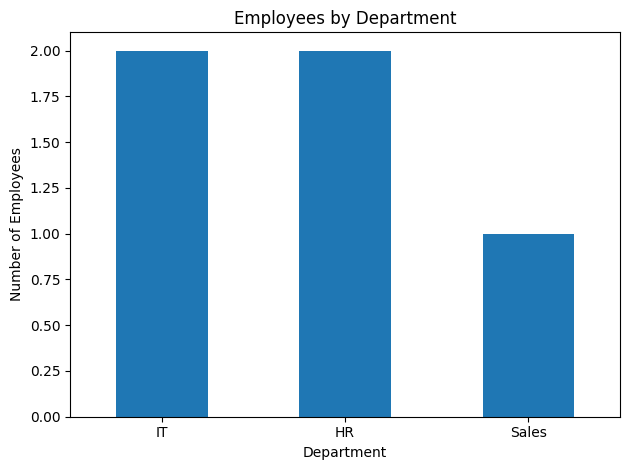

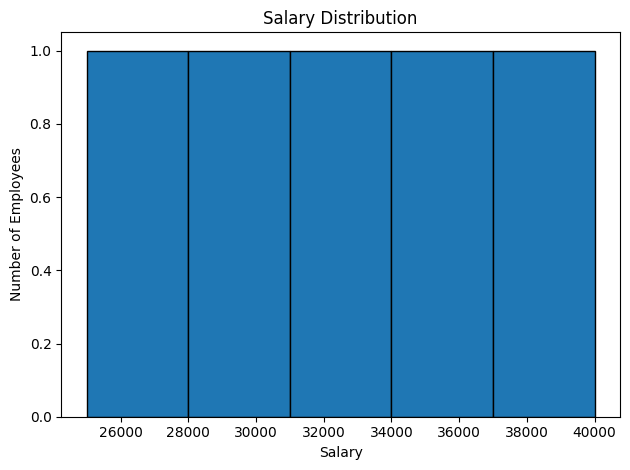

In [5]:
# Chart 1: Employees in each department
df["Department"].value_counts().plot(kind="bar")

plt.title("Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 2: Salary distribution
plt.figure()
plt.hist(df["Salary"], bins=5, edgecolor="black")

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

In [6]:
# Get sample user data from a REST API
url = "https://jsonplaceholder.typicode.com/users"

response = requests.get(url, timeout=20)

print("Status Code:", response.status_code)

response.raise_for_status()

users = response.json()

api_df = pd.DataFrame(users)

print("API Data:")
display(api_df[["id", "name", "email", "city"]]
        if "city" in api_df.columns
        else api_df[["id", "name", "email"]])

Status Code: 200
API Data:


,id,name,email
0,1,Leanne Graham,Sincere@april.biz
1,2,Ervin Howell,Shanna@melissa.tv
2,3,Clementine Bauch,Nathan@yesenia.net
3,4,Patricia Lebsack,Julianne.OConner@kory.org
4,5,Chelsey Dietrich,Lucio_Hettinger@annie.ca
5,6,Mrs. Dennis Schulist,Karley_Dach@jasper.info
6,7,Kurtis Weissnat,Telly.Hoeger@billy.biz
7,8,Nicholas Runolfsdottir V,Sherwood@rosamond.me
8,9,Glenna Reichert,Chaim_McDermott@dana.io
9,10,Clementina DuBuque,Rey.Padberg@karina.biz


In [7]:
api_df = pd.json_normalize(users)

api_df = api_df[[
    "id", "name", "email", "address.city"
]]

api_df = api_df.rename(
    columns={"address.city": "city"}
)

display(api_df)

# Save API results
api_df.to_csv("api_users.csv", index=False)

,id,name,email,city
0,1,Leanne Graham,Sincere@april.biz,Gwenborough
1,2,Ervin Howell,Shanna@melissa.tv,Wisokyburgh
2,3,Clementine Bauch,Nathan@yesenia.net,McKenziehaven
3,4,Patricia Lebsack,Julianne.OConner@kory.org,South Elvis
4,5,Chelsey Dietrich,Lucio_Hettinger@annie.ca,Roscoeview
5,6,Mrs. Dennis Schulist,Karley_Dach@jasper.info,South Christy
6,7,Kurtis Weissnat,Telly.Hoeger@billy.biz,Howemouth
7,8,Nicholas Runolfsdottir V,Sherwood@rosamond.me,Aliyaview
8,9,Glenna Reichert,Chaim_McDermott@dana.io,Bartholomebury
9,10,Clementina DuBuque,Rey.Padberg@karina.biz,Lebsackbury


In [8]:
# Save cleaned dataset
df.to_csv("cleaned_employee_data.csv", index=False)

# Generate report
report = f"""
PYTHON DATA ANALYSIS REPORT

1. Total employees: {len(df)}
2. Average salary: {df['Salary'].mean():.2f}
3. Average age: {df['Age'].mean():.2f}

Employees by department:
{df['Department'].value_counts().to_string()}

Salary statistics:
{df['Salary'].describe().to_string()}
"""

with open("analysis_report.txt", "w") as file:
    file.write(report)

print(report)
print("Report and cleaned dataset saved successfully.")


PYTHON DATA ANALYSIS REPORT

1. Total employees: 5
2. Average salary: 32500.00
3. Average age: 24.75

Employees by department:
Department
IT       2
HR       2
Sales    1

Salary statistics:
count        5.000000
mean     32500.000000
std       5590.169944
min      25000.000000
25%      30000.000000
50%      32500.000000
75%      35000.000000
max      40000.000000

Report and cleaned dataset saved successfully.


In [9]:
from google.colab import files

files.download("cleaned_employee_data.csv")
files.download("analysis_report.txt")
files.download("api_users.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>